# TFP shock with sticky wages: minimising the output gap

Monetary policy is chosen to minimise the **output gap** rather than the deviation of
output from its steady state. Two scenarios:

1. **No time to build** — every firm reprices immediately.
2. **Exogenous time to build** — firms reprice with the calibrated lag $\tau$.

The gap is $x_t = y_t - y^n_t$ with flexible-wage natural output
$y^n_t = \frac{1+\eta}{\gamma+\eta}a_t$, and the loss is $\sum_t x_t^2$ (no inflation term).

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import itertools

/Users/samuelzhao/anaconda3/lib/python3.10/site-packages/pandas/core/arrays/masked.py:61: UserWarning: Pandas requires version '1.3.6' or newer of 'bottleneck' (version '1.3.5' currently installed).
  from pandas.core import (


## 1. Calibration

/var/folders/26/bmvk0hrd5xbgcvl_s6s42rf80000gn/T/ipykernel_6408/1609946583.py:7: UserWarning: Could not infer format, so each element will be parsed individually, falling back to `dateutil`. To ensure parsing is consistent and as-expected, please specify a format.
  data = pd.read_csv('APP_data_usa_goods.csv', index_col=0, parse_dates=True)


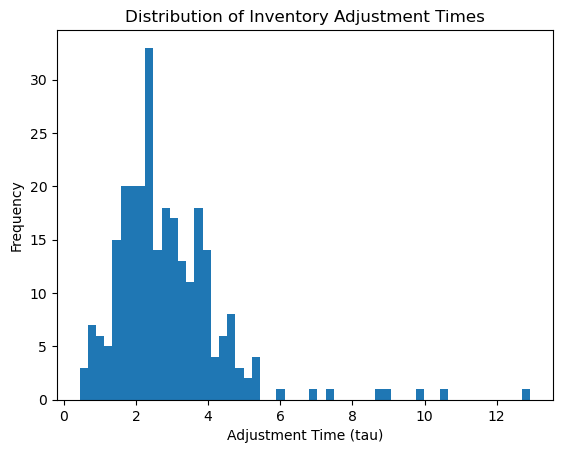

In [2]:
# Economic model constants
INVENTORY_TO_COGS_SCALING = 36.5
DAYS_PER_MONTH = 30
TAX_RATE = 0.1
HISTOGRAM_BINS = 55

data = pd.read_csv('APP_data_usa_goods.csv', index_col=0, parse_dates=True)
data_tau = (data['invtCogsRatio'] * INVENTORY_TO_COGS_SCALING / (DAYS_PER_MONTH * TAX_RATE))

plt.hist(data_tau, bins=HISTOGRAM_BINS)
plt.title('Distribution of Inventory Adjustment Times')
plt.xlabel('Adjustment Time (tau)'); plt.ylabel('Frequency')
plt.show()

### Preferences

$\gamma$ is relative risk aversion (it is also the slope of the IS curve) and $\eta$ is the
inverse Frisch elasticity. They enter the gap only through
$\varphi_{ya} = \frac{1+\eta}{\gamma+\eta}$.

**$\gamma = 1$ is a degenerate case for a TFP shock.** Under a constant nominal rate the IS
curve gives $y_t = \frac{1}{\gamma}a_t$, while $y^n_t = \varphi_{ya}a_t$. At $\gamma=1$ both
coefficients equal $1$ *for any* $\eta$, so $x_t \equiv 0$ whatever policy does — a divine
coincidence, and the loss is zero everywhere. The baseline below therefore uses
$\gamma = 2$; set `gamma = 1.0` to reproduce the degenerate case.

In [3]:
NOMINAL_INTEREST_RATE = 0.01   # 1% per period
INVENTORY_DURATION = 30        # days
ADJUSTMENT_RATE = 0.9

beta = 1 / (1.0 + NOMINAL_INTEREST_RATE)
beta1 = 1 / (1.0 + NOMINAL_INTEREST_RATE * np.exp(INVENTORY_DURATION /
                                                  (INVENTORY_TO_COGS_SCALING * ADJUSTMENT_RATE)))
beta_hh = beta
W = 1
sigma = 5                      # CES elasticity across firms

gamma = 2.0                    # relative risk aversion / IS slope   (gamma = 1 -> zero gap)
eta = 2.0                      # inverse Frisch elasticity
PHI_YA = (1 + eta) / (gamma + eta)
rho = 1 / beta_hh - 1

print(f'gamma={gamma}, eta={eta}  ->  IS slope 1/gamma={1/gamma:.4f}, '
      f'phi_ya={PHI_YA:.4f}, gap coefficient={1/gamma - PHI_YA:+.4f}')

gamma=2.0, eta=2.0  ->  IS slope 1/gamma=0.5000, phi_ya=0.7500, gap coefficient=-0.2500


In [4]:
EPSILON = 1e-10
tau_diff = np.zeros((1000, 1))

for i, c in enumerate(np.linspace(0, 0.99, 1000)):
    if beta * c <= EPSILON or beta1 * c <= EPSILON:
        tau_diff[i] = np.inf
        continue
    N = -(data_tau) - 1 / np.log(beta * c)
    tau1 = -1 / np.log(beta * c) - N;   tau1[tau1 < 0] = 0
    tau2 = -1 / np.log(beta1 * c) - N;  tau2[tau2 < 0] = 0
    tau_diff[i] = np.mean(np.abs(tau1 - tau2))

c_list = np.linspace(0, 0.99, 1000)
optimal_c_value = c_list[np.where(np.abs(tau_diff - 1) == np.min(np.abs(tau_diff - 1)))[0]]
print('optimal c:', optimal_c_value)

optimal c: [0.9018018]


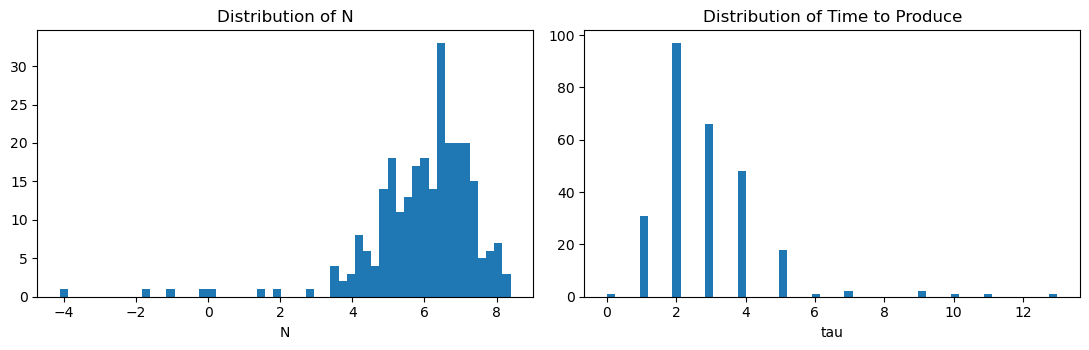

In [5]:
N = -data_tau - 1/np.log(beta_hh * optimal_c_value)
tau = -1/np.log(beta_hh * optimal_c_value) - N
tau[tau < 0] = 0
tau_floor, tau_ceil = np.floor(tau), np.ceil(tau)
tprod_ceil = (beta_hh * optimal_c_value)**tau_ceil * (tau_ceil + N)
tprod_floor = (beta_hh * optimal_c_value)**tau_floor * (tau_floor + N)
tau[(tprod_ceil - tprod_floor) > 0] = tau_ceil[(tprod_ceil - tprod_floor) > 0]
tau[(tprod_ceil - tprod_floor) < 0] = tau_floor[(tprod_ceil - tprod_floor) < 0]
tau[tau < 0] = 0

fig, ax = plt.subplots(1, 2, figsize=(11, 3.6))
ax[0].hist(N, bins=HISTOGRAM_BINS); ax[0].set_title('Distribution of N'); ax[0].set_xlabel('N')
ax[1].hist(tau, bins=HISTOGRAM_BINS); ax[1].set_title('Distribution of Time to Produce')
ax[1].set_xlabel('tau')
plt.tight_layout(); plt.show()

In [6]:
def generate_pattern_array_with_extra_rows(tau):
    """Staggering matrix: which firms have re-optimised by period t (shock factor 0.97)."""
    tau = np.asarray(tau)
    if tau.size == 0:
        raise ValueError("tau array cannot be empty")
    if np.any(tau < 0):
        raise ValueError("tau values must be non-negative")

    n = len(tau) + int(np.min(tau))
    m = int(np.max(tau)) + int(np.min(tau))
    missing_count = len(set(range(int(max(tau)) + 1)) - set(tau))

    A = np.ones((m + 2, n + missing_count), dtype=float)
    count = 0
    for i in range(1, m + 2):
        firms_adjusting = tau[tau == i - 1]
        for j in range(len(firms_adjusting)):
            A[i, n - i - j - count] = 0.97
        if len(firms_adjusting) > 1:
            count += len(firms_adjusting) - 1

    A_extended = np.vstack([A, np.ones(n + missing_count, dtype=float)])
    return A_extended[:, 0:n - int(np.min(tau))]

## 2. The IS curve in gap form

The gap obeys its own recursion, anchored on the **natural rate of interest** rather than
on the steady state:

$$x_t = x_{t+1} - \frac{1}{\gamma}\bigl(i_t - \pi_{t+1} - r^n_t\bigr), \qquad x_T = 0$$

$$y^n_t = \frac{1+\eta}{\gamma+\eta}a_t, \qquad
  r^n_t = \rho + \gamma\,(y^n_{t+1}-y^n_t), \qquad \pi_t = -\Delta a_t$$

Fixed wages with flexible prices give $\pi_t = -\Delta a_t$. The gap closes when the
**real** rate equals the natural rate, $i_t = r^n_t + \mathbb{E}_t\pi_{t+1}$.

In [7]:
def euler_path_gap(i_path, a_level, gamma=2.0, eta=2.0, beta_hh=1/(1+0.01), a_prev=0.0):
    """
    IS curve in output-gap form.  Returns (x, pi, y_nat, r_nat).

        x_t = x_{t+1} - (1/gamma) * ( i_t - pi_{t+1} - r^n_t ),   x_T = 0

    Forward terms pi_{t+1} and Delta y^n_{t+1} are set to 0 in the last period.
    """
    i_path = np.asarray(i_path, float)
    a_level = np.asarray(a_level, float)
    if i_path.shape != a_level.shape:
        raise ValueError("Shapes must match.")
    if gamma <= 0:
        raise ValueError("gamma>0 required.")

    T = len(i_path)
    rho = 1.0 / beta_hh - 1.0
    phi_ya = (1.0 + eta) / (gamma + eta)

    da = np.empty(T)
    da[0] = a_level[0] - a_prev
    da[1:] = a_level[1:] - a_level[:-1]
    pi = -da

    y_nat = phi_ya * a_level
    dy_nat_fwd = np.r_[y_nat[1:] - y_nat[:-1], 0.0]
    r_nat = rho + gamma * dy_nat_fwd
    pi_fwd = np.r_[pi[1:], 0.0]

    x = np.zeros(T + 1)
    for t in range(T - 1, -1, -1):
        x[t] = x[t + 1] - (1.0 / gamma) * (i_path[t] - pi_fwd[t] - r_nat[t])

    return x[:T], pi, y_nat, r_nat

In [8]:
def summarise(label, dev, r_arrange, matches, r_choice, X_gap):
    """Standard summary block for a gap experiment."""
    dev = np.asarray(dev).ravel()
    best = int(np.argmin(dev))
    base = int(np.where(matches)[0][0])
    w = 46
    print('=' * 68)
    print(label)
    print('=' * 68)
    print(f'{"loss  sum x_t^2,  no policy change":<{w}}: {dev[base]:.4e}')
    print(f'{"loss  sum x_t^2,  gap-minimising policy":<{w}}: {dev[best]:.4e}')
    if dev[base] > 1e-20:
        print(f'{"reduction in loss":<{w}}: {100*(1-dev[best]/dev[base]):.1f}%')
    print(f'{"peak |x_t|,  no policy change":<{w}}: {np.max(np.abs(X_gap[base])):.4e}')
    print(f'{"peak |x_t|,  gap-minimising policy":<{w}}: {np.max(np.abs(X_gap[best])):.4e}')
    print(f'{"rate sequence,  no policy change":<{w}}: {np.round(r_arrange[base], 6)}')
    print(f'{"rate sequence,  gap-minimising policy":<{w}}: {np.round(r_arrange[best], 6)}')
    on_bound = bool(np.any(np.isclose(r_arrange[best], r_choice[0]) |
                           np.isclose(r_arrange[best], r_choice[-1])))
    print(f'{"grid":<{w}}: {len(r_choice)} points on '
          f'[{r_choice[0]:g}, {r_choice[-1]:g}]')
    print(f'{"optimum sits on a grid bound":<{w}}: {on_bound}')
    if on_bound:
        print('   -> the optimum may not be interior; widen r_choice to check.')
    return best, base


def gap_figure(label, X_gap, I_path, best, base, fname, horizon=20):
    """Standard 2-panel gap figure: the output gap and the rate path, same horizon."""
    fig, axes = plt.subplots(1, 2, figsize=(12, 4.2))
    t = np.arange(horizon)

    axes[0].plot(t, X_gap[base][:horizon], lw=2, label='no policy change')
    axes[0].plot(t, X_gap[best][:horizon], '--', lw=2, label='gap-minimising policy')
    axes[0].axhline(0, color='k', lw=0.8)
    axes[0].set_xlabel('Time'); axes[0].set_ylabel('$x_t = y_t - y^n_t$')
    axes[0].set_xlim(0, horizon - 1)
    axes[0].set_title('Output gap')
    axes[0].legend(fontsize=8)

    axes[1].step(t, I_path[base][:horizon], where='post', lw=2, label='no policy change')
    axes[1].step(t, I_path[best][:horizon], where='post', linestyle='--', lw=2,
                 label='gap-minimising policy')
    axes[1].set_xlabel('Time'); axes[1].set_ylabel('$i_t$')
    axes[1].set_xlim(0, horizon - 1)
    axes[1].set_title('Nominal interest rate')
    axes[1].legend(fontsize=8)

    fig.suptitle(label, fontsize=13)
    plt.tight_layout()
    plt.savefig(fname, dpi=150, bbox_inches='tight')
    plt.show()

## 3. Gap results: no time to build

Every firm reprices immediately, so aggregate TFP is just the shock itself: a one-time
$-1\%$ level drop at $t=0$.

In [9]:
T = 10
sequence_length = 5
r_choice = np.linspace(0, 0.0125, 6)
r_arrange = np.array(list(itertools.product(r_choice, repeat=sequence_length)))
size = r_arrange.shape[0]

deviation_gap = np.zeros(size)
Y_output = np.zeros((size, T))
Y_natural = np.zeros((size, T))
X_gap = np.zeros((size, T))
I_path_store = np.zeros((size, T))

for k, r_vec in enumerate(r_arrange):
    i_path = np.full(T, rho, dtype=float)
    i_path[:sequence_length] = r_vec

    a_level = np.zeros(T, dtype=float)
    a_level[0] = -0.01                      # 1 percent decrease in A

    x, pi, y_nat, r_nat = euler_path_gap(i_path, a_level, gamma=gamma, eta=eta,
                                         beta_hh=beta_hh, a_prev=0.0)

    X_gap[k] = x
    Y_natural[k] = y_nat
    Y_output[k] = x + y_nat
    I_path_store[k] = i_path
    deviation_gap[k] = np.sum(x**2)

matches = np.all(np.isclose(r_arrange, rho), axis=1)
best_ntb, base_ntb = summarise('1 percent decrease in A -- No time to build',
                               deviation_gap, r_arrange, matches, r_choice, X_gap)

1 percent decrease in A -- No time to build
loss  sum x_t^2,  no policy change            : 6.2500e-06
loss  sum x_t^2,  gap-minimising policy       : 1.5625e-06
reduction in loss                             : 75.0%
peak |x_t|,  no policy change                 : 2.5000e-03
peak |x_t|,  gap-minimising policy            : 1.2500e-03
rate sequence,  no policy change              : [0.01 0.01 0.01 0.01 0.01]
rate sequence,  gap-minimising policy         : [0.0125 0.0125 0.01   0.01   0.01  ]
grid                                          : 6 points on [0, 0.0125]
optimum sits on a grid bound                  : True
   -> the optimum may not be interior; widen r_choice to check.


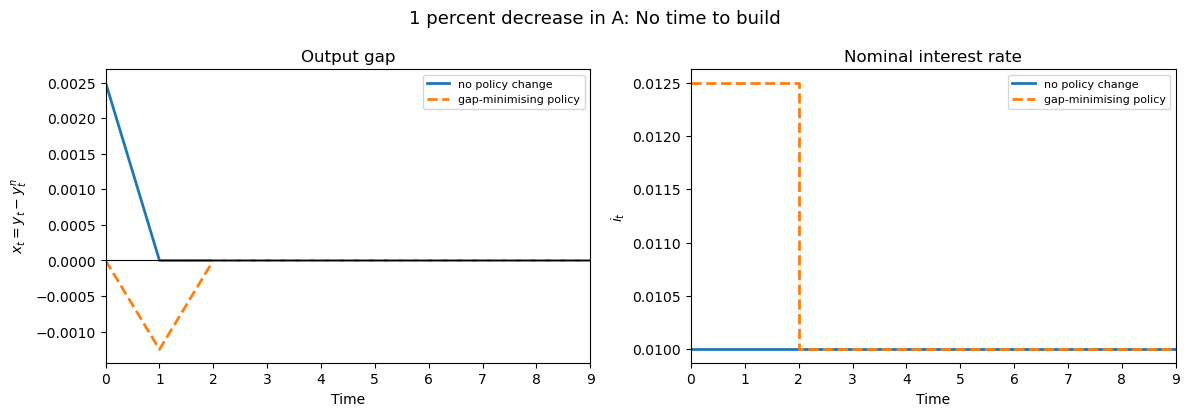

In [10]:
gap_figure('1 percent decrease in A: No time to build',
           X_gap, I_path_store, best_ntb, base_ntb,
           '../semi_endo_A_gap_no_time_to_build.png', horizon=10)

## 4. Gap results: exogenous time to build

Firms reprice with the calibrated lag $\tau$, so aggregate TFP follows the staggered path
$a_t = \log A_t - \log A_T$. Note $a_t$ is itself rate-dependent: policy moves potential
output through the time-to-produce channel.

In [11]:
T = 30
sequence_length = 4
r_choice = np.linspace(0, 0.0125, 6)
r_arrange = np.array(list(itertools.product(r_choice, repeat=sequence_length)))
size = r_arrange.shape[0]

deviation_gap = np.zeros(size)
Y_output = np.zeros((size, T))
Y_natural = np.zeros((size, T))
X_gap = np.zeros((size, T))
A_bar_store = np.zeros((size, T))
I_path_store = np.zeros((size, T))

tvals = tau.astype(int).to_numpy()
N_array = np.array(N)
A_pattern = generate_pattern_array_with_extra_rows(tau)

for k in range(size):
    n = sequence_length
    r = np.asarray(r_arrange[k], dtype=float)

    interest_rate_list = np.ones((T, T)) * rho
    arr2d = np.full((n, n), rho, dtype=float)
    for i in range(n):
        arr2d[i, :i+1] = r[i::-1]
    interest_rate_list[0:n, :n] = arr2d

    beta_mat = 1.0 / (1.0 + interest_rate_list)
    cumprod_ext = np.ones((T, T + 1))
    cumprod_ext[:, 1:] = np.cumprod(beta_mat, axis=1)
    beta_prod = cumprod_ext[:, tvals]

    tprod_array = np.array((beta_prod * optimal_c_value) *
                           ((tvals + N_array) * np.ones((T, 269))))
    prod_shock = np.ones((T, 269))
    prod_shock[0:15] = A_pattern[1:]
    A_prod = np.sum((prod_shock * tprod_array)**(sigma - 1), axis=1)**(1/(sigma - 1))

    i_path = np.ones(T) * rho
    i_path[0:sequence_length] = r_arrange[k]
    abar = np.log(A_prod) - np.log(A_prod)[-1]

    x, pi, y_nat, r_nat = euler_path_gap(i_path, abar, gamma=gamma, eta=eta,
                                         beta_hh=beta_hh, a_prev=0)

    X_gap[k] = x
    Y_natural[k] = y_nat
    Y_output[k] = x + y_nat
    I_path_store[k] = i_path
    A_bar_store[k] = abar
    deviation_gap[k] = np.sum(x**2)

matches = np.all(np.isclose(r_arrange, rho), axis=1)
best_ttb, base_ttb = summarise('3 percent decrease in A -- Exogenous time to build',
                               deviation_gap, r_arrange, matches, r_choice, X_gap)

3 percent decrease in A -- Exogenous time to build
loss  sum x_t^2,  no policy change            : 1.2708e-05
loss  sum x_t^2,  gap-minimising policy       : 3.4791e-06
reduction in loss                             : 72.6%
peak |x_t|,  no policy change                 : 2.6399e-03
peak |x_t|,  gap-minimising policy            : 1.4269e-03
rate sequence,  no policy change              : [0.01 0.01 0.01 0.01]
rate sequence,  gap-minimising policy         : [0.0075 0.0075 0.01   0.0125]
grid                                          : 6 points on [0, 0.0125]
optimum sits on a grid bound                  : True
   -> the optimum may not be interior; widen r_choice to check.


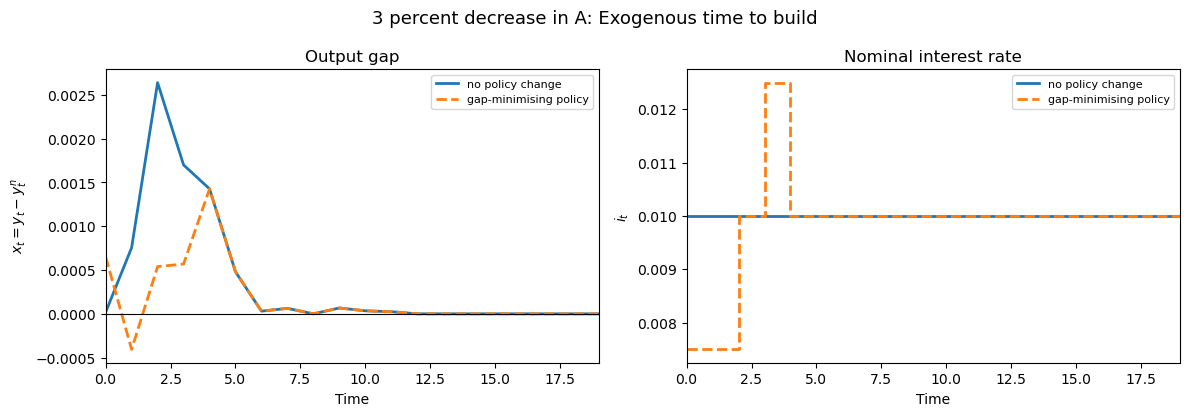

In [12]:
gap_figure('3 percent decrease in A: Exogenous time to build',
           X_gap, I_path_store, best_ttb, base_ttb,
           '../semi_endo_A_gap_exogenous_time_to_build.png', horizon=20)

## Escalating the policy horizon

Every optimum above sits on a bound of `r_choice`, which means the answer is being shaped
by the grid and by the short window of policy freedom rather than by the economics. This
section grows the number of free periods $L$ — everything after $L$ stays pinned at $\rho$
— and re-solves, stopping when the **last free period comes back to $\rho$**. At that
point the horizon is long enough that pinning the tail no longer binds.

Grid enumeration is $6^L$ and blows up immediately, so this uses a bounded continuous
solve (L-BFGS-B on $[0,\,0.05]$, the lower bound being the ZLB) instead of enumerating.

In [13]:
from scipy.optimize import minimize


def escalate(objective, T, L_start=3, L_max=16, tol=1e-4, bounds=(0.0, 0.05)):
    """
    Grow the number of free policy periods L until the optimal sequence's LAST free
    period returns to rho.  `objective(r_vec, T)` is MINIMISED (pass -utility for the
    planner problems).  Returns (history, settled_L); settled_L is None if it never
    settles by L_max.
    """
    hist = []
    print(f'{"L":>3} {"last i_t":>10} {"settled":>8} {"objective":>15}   optimal sequence')
    print('-' * 92)
    for L in range(L_start, L_max + 1):
        res = minimize(lambda r: objective(r, T), np.ones(L) * rho,
                       method='L-BFGS-B', bounds=[bounds] * L,
                       options={'maxiter': 20000, 'ftol': 1e-18, 'gtol': 1e-14})
        settled = bool(np.isclose(res.x[-1], rho, atol=tol))
        hist.append((L, res.x.copy(), float(res.fun), settled))
        print(f'{L:>3} {res.x[-1]:>10.6f} {str(settled):>8} {res.fun:>15.6e}   '
              f'{np.round(res.x[:8], 5)}{" ..." if L > 8 else ""}')
        if settled:
            print(f'\n-> settles at L = {L}: the last free period is back at '
                  f'rho = {rho:.4f}')
            return hist, L
    print(f'\n-> NOT settled by L = {L_max}: the optimum is still away from rho.')
    return hist, None


def escalate_figure(hist, settled_L, label, fname):
    """Objective against L, and the rate path at the final L."""
    Ls = [h[0] for h in hist]
    objs = [h[2] for h in hist]
    r_last = hist[-1][1]

    fig, axes = plt.subplots(1, 2, figsize=(12, 4.2))
    axes[0].plot(Ls, objs, 'o-')
    axes[0].set_yscale('symlog', linthresh=1e-18)
    axes[0].set_xlabel('free policy periods $L$'); axes[0].set_ylabel('objective')
    axes[0].set_title('Objective as the horizon grows')

    p = np.arange(len(r_last))
    axes[1].step(p, r_last, where='post', lw=2, label=f'optimal $i_t$ at L={Ls[-1]}')
    axes[1].axhline(rho, color='k', lw=0.8, linestyle='--', label=r'$\rho$')
    axes[1].set_xlabel('Period'); axes[1].set_ylabel('$i_t$')
    axes[1].set_title('Optimal rate path at the final $L$')
    axes[1].legend(fontsize=8)

    status = f'settles at L={settled_L}' if settled_L else 'does not settle'
    fig.suptitle(f'{label}  ({status})', fontsize=13)
    plt.tight_layout()
    plt.savefig(fname, dpi=150, bbox_inches='tight')
    plt.show()

In [14]:
def tfp_from_rates(r, T):
    L = len(r)
    interest_rate_list = np.ones((T, T)) * rho
    arr2d = np.full((L, L), rho, dtype=float)
    for i in range(L):
        arr2d[i, :i+1] = np.asarray(r, float)[i::-1]
    interest_rate_list[0:L, :L] = arr2d
    ce = np.ones((T, T + 1))
    ce[:, 1:] = np.cumprod(1.0/(1.0 + interest_rate_list), axis=1)
    bp = ce[:, tvals]
    tp = (bp * optimal_c_value) * ((tvals + N_array) * np.ones((T, 269)))
    ps = np.ones((T, 269)); ps[0:15] = A_pattern[1:]
    A = np.sum((ps * tp)**(sigma - 1), axis=1)**(1/(sigma - 1))
    return np.log(A) - np.log(A)[-1]


def obj_gap_ntb(r, T):
    ip = np.ones(T) * rho; ip[:len(r)] = r
    a = np.zeros(T); a[0] = -0.01
    x, *_ = euler_path_gap(ip, a, gamma=gamma, eta=eta, beta_hh=beta_hh, a_prev=0.0)
    return np.sum(x**2)


def obj_gap_ttb(r, T):
    ip = np.ones(T) * rho; ip[:len(r)] = r
    x, *_ = euler_path_gap(ip, tfp_from_rates(r, T), gamma=gamma, eta=eta,
                           beta_hh=beta_hh, a_prev=0)
    return np.sum(x**2)


print('NO TIME TO BUILD')
hist_ntb, L_ntb = escalate(obj_gap_ntb, 10, L_start=3, L_max=9)
print()
print('EXOGENOUS TIME TO BUILD')
hist_ttb, L_ttb = escalate(obj_gap_ttb, 30, L_start=3, L_max=16)

NO TIME TO BUILD
  L   last i_t  settled       objective   optimal sequence
--------------------------------------------------------------------------------------------
  3   0.010000     True    1.756552e-17   [0.015 0.01  0.01 ]

-> settles at L = 3: the last free period is back at rho = 0.0100

EXOGENOUS TIME TO BUILD
  L   last i_t  settled       objective   optimal sequence
--------------------------------------------------------------------------------------------
  3   0.015667    False    5.168190e-06   [0.0119  0.00341 0.01567]
  4   0.014248    False    2.276820e-06   [0.01028 0.00649 0.00916 0.01425]
  5   0.014022    False    2.408845e-07   [0.01101 0.00509 0.0121  0.00831 0.01402]
  6   0.012323    False    1.098078e-08   [0.0108  0.00549 0.01126 0.01    0.01056 0.01232]
  7   0.011214    False    1.004711e-08   [0.01086 0.00539 0.01148 0.00957 0.01144 0.01052 0.01121]
  8   0.010924    False    6.187053e-09   [0.01084 0.00542 0.0114  0.00973 0.01111 0.01119 0.00984 0.0109

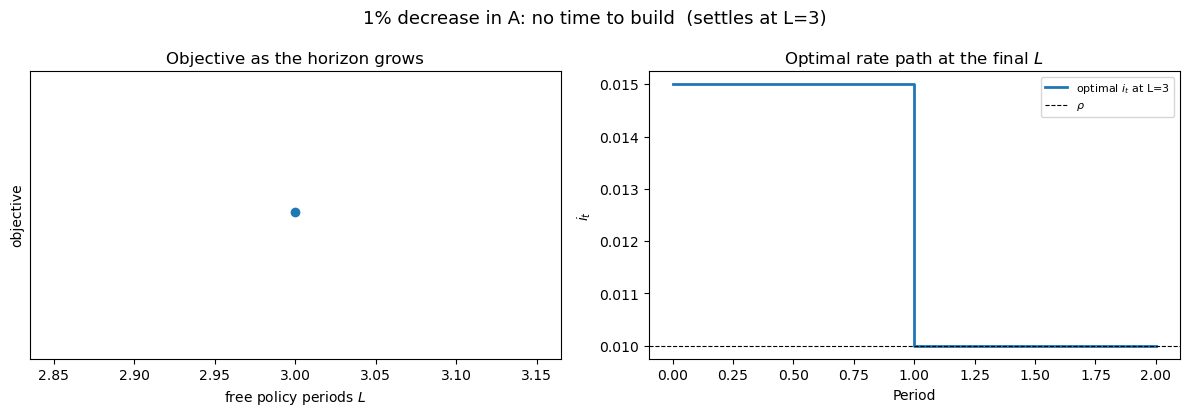

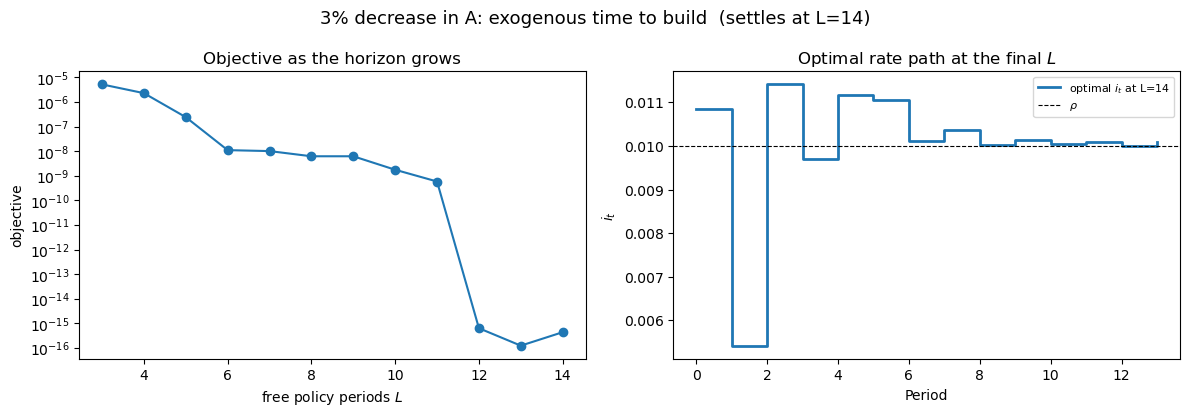

In [15]:
escalate_figure(hist_ntb, L_ntb, '1% decrease in A: no time to build',
                '../semi_endo_A_gap_escalate_no_time_to_build.png')
escalate_figure(hist_ttb, L_ttb, '3% decrease in A: exogenous time to build',
                '../semi_endo_A_gap_escalate_exogenous_time_to_build.png')